### 1. A nasty integral

Using Monte Carlo integration, check that

$$ \int_0^\infty x^3 \exp\left(-\frac{x^2}{2\sigma^2}\right) \,dx = 2\sigma^4 .$$

- Does the result converge with the number of samples? And how does the error go down?
- Do it many times. For a given $N$, how are the result distributed? We'll talk about model fitting at lenght later on, but for now try to fit it by hand with a parametrized model. (If N is large enough you should get something that looks *very* accurate! And if $N$ is small?)
- How does the distribution change if $N$ increases?

(Hint: think about sample mean and sample variance)


In [59]:
import numpy as np 
import matplotlib.pyplot as plt 
import scipy.stats

In [60]:
xmax = 100
xmin = 0 

N = 10000

sigma = 1 

xi = np.random.uniform(xmin, xmax, N)

def fun(x):
    return x**3 * np.exp(-x**2/(2*sigma))

integral = (xmax - xmin) * np.mean(fun(xi))

integral


2.1282930355260654

In [61]:
true = 2 * sigma**4
Ns = np.unique(np.logspace(1, 6, 100, dtype=int)) #unique cancel duplicate and order the array  # 10 ... 1,000,000

est = np.array([(xmax - xmin)*np.mean(fun(np.random.uniform(xmin,xmax,N))) for N in Ns])
rel_err = np.abs(est - true)/true


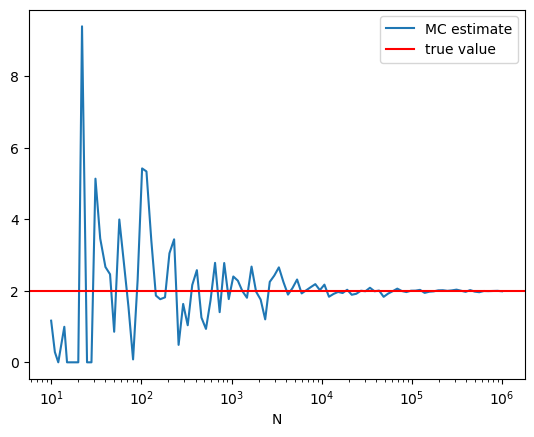

In [62]:
plt.plot(Ns, est, label="MC estimate")
plt.axhline(true, c='r', label="true value")
plt.xscale('log')
plt.xlabel("N"); plt.legend(); plt.show()

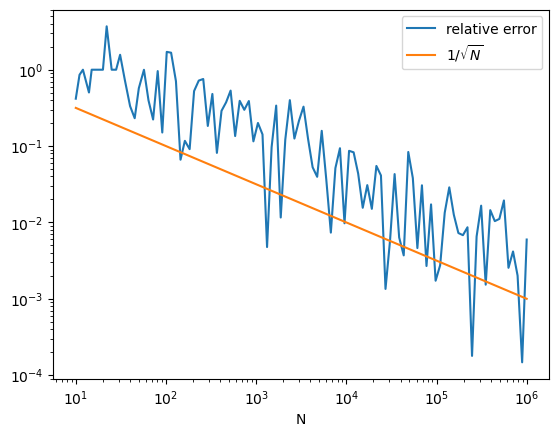

In [63]:
plt.plot(Ns, rel_err, label="relative error")
plt.plot(Ns, Ns**-0.5, label=r"$1/\sqrt{N}$")
plt.loglog()
plt.xlabel("N"); plt.legend(); plt.show()

In [64]:
def estimate(N): 
    xi = np.random.uniform(xmin, xmax, N)
    return (xmax - xmin) * np.mean(fun(xi))

def repeat(N, n_trials=1000):
    return np.array([estimate(N) for _ in range(n_trials)])

<function matplotlib.pyplot.show(close=None, block=None)>

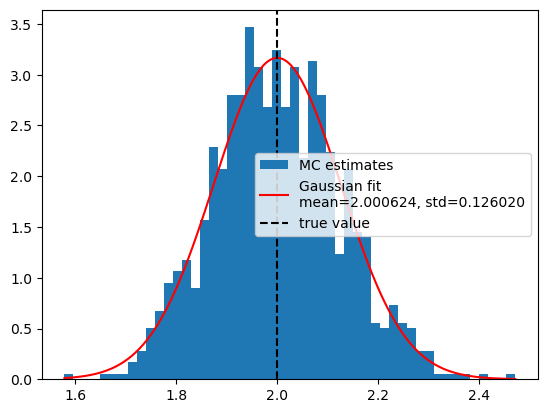

In [65]:
# One N, many repetitions, hand gaussian fit 

res = repeat(N)
mu, std = res.mean(), res.std(ddof=1)

plt.hist(res, bins=50, density=True, label='MC estimates')
x = np.linspace(res.min(), res.max(), 500)
plt.plot(x, scipy.stats.norm(mu,std).pdf(x), 'r', label=f"Gaussian fit\nmean={mu:3f}, std={std:3f}")
plt.axvline(true, c='k', ls='--', label='true value')
plt.legend();
plt.show